# Average Counts of Any Patents and of Privacy Patents Filed in the Year, Highest and Lowest Topic-Relevance Quartiles Among Patenting Sample Firms, 1999 to 2021

| Item | Description |
|---|---|
| Goal | Two figures that compare the sample firms most and least relevant to the consumer data privacy topic on their patenting over time. The analysis sample is every T3 sample firm with at least one KPSS patent, in any technology, filed in 1999 to 2017. Those firms are split into quartiles of the main topic-relevance score, and the highest quartile is compared with the lowest on the average count of any patents filed in the year per firm , 1999 to 2021: any patents (all KPSS patents, in any technology) in Figure 1 and privacy patents in Figure 2. The two outcomes are always named any patents or privacy patents so that they cannot be confused. |
| Input | `Processed/sample_firm_patents.parquet` from T4.1.1 (one row per KPSS patent filed by a sample firm, with the firm and the filing year); `Processed/privacy_patents.parquet` from T4.1.2 (one row per privacy patent); `output/T3.8.3/firm_relevance_scores_wide.csv` from T3 (one row per firm and sample with the relevance measures); `output/T4.1.1/patent_counts_by_firm.csv` (the 1,058 sample firms with names); `privacy_cpc/privacy_cpc_codes.xlsx` for the number of privacy codes named in the Notes. |
| Output | In `output/T4.1.3`: `analysis_sample_firms.csv` (one row per analysis-sample firm with its score, quartile, and patent counts), `average_patent_counts_by_quartile_year.csv` (one row per quartile and filing year with the number of firms, the total and the average counts of all and of privacy patents), and the figures `fig_1_average_patent_count_highest_vs_lowest_relevance_quartile.{png,svg,pdf}` and `fig_2_average_privacy_patent_count_highest_vs_lowest_relevance_quartile.{png,svg,pdf}`. |
| Unit | A firm (gvkey) for the sample and the quartiles; a firm-year for the counts, averaged over the firms of a quartile. |
| Analysis sample | Firms of the all-years T3 sample (1,058 firms) with at least one KPSS patent filed in `PATENTING_START` to `PATENTING_END` (1999 to 2017), in any CPC class. Firms without a patent in those years are left out, so the comparison is among firms that patent at all. |
| Topic relevance | `MEASURE_ID`, the main T3 measure: the cosine similarity between a firm-level summary of the firm's 10-K Item 1 sections and the policy summary of legislator statements on consumer data privacy legislation (T3.8.3, all-years sample), one score per firm. Quartiles are cut within the analysis sample with `pd.qcut`; quartile 4 is the highest relevance and quartile 1 the lowest. |
| Outcomes | For each firm and filing year from `PERIOD_START` to `PERIOD_END` (1999 to 2021): the count of any patents filed (all KPSS patents, Figure 1) and the count of privacy patents filed (Figure 2), where a privacy patent carries at least one code of the project's privacy code list as defined in T4.1.2. A firm without a patent in a year counts zero. |
| Average | The quartile's total count in the year divided by its number of firms, which is fixed over the period: a firm counts zero in years in which it filed nothing, including years before it was listed or after it was delisted. The median across firms is saved in the table for reference. |
| Variables | • `quartile`: $q_i \in \{1, 2, 3, 4\}$, the quartile of firm $i$'s topic-relevance score $s_i$ within the analysis sample, 4 the highest<br>• `n_patents`: $N_{it} = \sum_{p \in i} \mathbb{1}[\text{filing year}_p = t]$, the count of any patents (all KPSS patents) firm $i$ filed in year $t$<br>• `n_privacy_patents`: $N^{\text{priv}}_{it} = \sum_{p \in i} \mathbb{1}[\text{filing year}_p = t]\, P_p$, the same count over privacy patents ($P_p = 1$)<br>• `mean_patents`, `mean_privacy_patents`: $\bar{N}_{qt} = \frac{1}{|q|}\sum_{i \in q} N_{it}$, the average over the firms of quartile $q$ in year $t$ |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, title and Notes in Markdown around the image. RED for the highest quartile and BLUE for the lowest, a legend below the X-title, a solid BLACK zero line; axis titles and legend entries in title case at the user's request. No vertical reference line. |

The KPSS data are to be cited as Kogan, L., Papanikolaou, D., Seru, A., and Stoffman, N. (2017), Technological Innovation, Resource Allocation, and Growth, *Quarterly Journal of Economics*, 132(2), 665 to 712, with the extended data from the authors' GitHub repository. See `T4.1.1` for the patent-to-firm link, `T4.1.2` for the privacy patents, and `T3.9.1` to `T3.9.4` for the relevance score.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the periods, the measure, and the wording

The two roots and the S5 folders. The patenting window that defines the analysis sample ends in 2017; the figures run to 2021.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SECTION = Path("T4 - Toy Example [Topic Relevance on Privacy Innovation]")
NOTEBOOK_SUBFOLDER = NOTEBOOK_SECTION / "T4.1 - Privacy Patents and Topic Relevance"
NOTEBOOK_NAME = "T4.1.3"  # the identifier names this notebook's output folder
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SECTION / "output" / NOTEBOOK_NAME
PATENTS_FILE = PROCESSED_FOLDER / "sample_firm_patents.parquet"  # T4.1.1
PRIVACY_PATENTS_FILE = PROCESSED_FOLDER / "privacy_patents.parquet"  # T4.1.2
PRIVACY_CODES_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "privacy_cpc/privacy_cpc_codes.xlsx"
FIRMS_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "output/T4.1.1/patent_counts_by_firm.csv"  # all 1,058 sample firms
SCORES_FILE = PROJECT_FOLDER / "T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.8.3/firm_relevance_scores_wide.csv"

PATENTING_START = 1999  # a firm enters the analysis sample with at least one patent filed in these years
PATENTING_END = 2017
PERIOD_START = 1999  # filing years drawn in the figures
PERIOD_END = 2021
N_QUANTILES = 4  # quartiles of the relevance score; the highest and the lowest are compared
HIGHEST, LOWEST = N_QUANTILES, 1
SAMPLE = "all_years"  # the T3 sample whose scores are used
MEASURE_ID = "summaries | policy_summary | firm_summary"  # the main relevance measure, as in T3.9.1 to T3.9.4

PERIOD_WORDS = f"{PERIOD_START} to {PERIOD_END}"
SCORE_WORDS = ("the cosine similarity between a firm-level summary of the firm's 10-K Item 1 (Business) sections over its sample fiscal years and the policy summary of legislator "
               "statements on consumer data privacy legislation, both written by the language model (T3.8.3, the main measure of T3.9.1 to T3.9.4); a higher score means that the "
               "firm's business description is closer to the policy summary")
GROUP_TITLES = {HIGHEST: "Highest Quartile of Topic Relevance", LOWEST: "Lowest Quartile of Topic Relevance"}
GROUP_COLORS = {HIGHEST: "RED", LOWEST: "BLUE"}  # names only; the figure cells map them to the S3 colors
SOURCE = ("KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in "
          "privacy_cpc/privacy_cpc_codes.xlsx; 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.3


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")  # tick labels with a thousands separator
COLOR_BY_NAME = {"RED": RED, "BLUE": BLUE}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the patents, the privacy patents, the sample firms, and the relevance scores

All KPSS patents of the sample firms and the privacy patents of T4.1.2, both restricted to the figure period; every privacy patent must be one of the sample-firm patents. The scores of the all-years sample, one per firm, must be complete.


In [4]:
patents = pd.read_parquet(PATENTS_FILE, columns=["patent_num", "gvkey", "filing_year"])
patents = patents.loc[patents["filing_year"].between(PERIOD_START, PERIOD_END)].reset_index(drop=True)
privacy_patents = pd.read_parquet(PRIVACY_PATENTS_FILE, columns=["patent_num", "gvkey", "filing_year"])
privacy_patents = privacy_patents.loc[privacy_patents["filing_year"].between(PERIOD_START, PERIOD_END)].reset_index(drop=True)
assert privacy_patents["patent_num"].isin(patents["patent_num"]).all(), "a privacy patent that is not a sample-firm patent"
N_PRIVACY_CODES = len(pd.read_excel(PRIVACY_CODES_FILE))
firms = pd.read_csv(FIRMS_FILE, dtype={"gvkey": str})[["gvkey", "conm"]]
scores = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
scores = scores.loc[scores["sample"].eq(SAMPLE), ["gvkey", MEASURE_ID]].rename(columns={MEASURE_ID: "relevance_score"})
assert scores["gvkey"].is_unique and scores["relevance_score"].notna().all()
firms = firms.merge(scores, on="gvkey", how="left", validate="one_to_one")
assert firms["relevance_score"].notna().all(), f"{int(firms['relevance_score'].isna().sum())} sample firms without a score"
print(f"Sample firms: {len(firms):,}; patents filed in {PERIOD_WORDS}: {len(patents):,} by {patents['gvkey'].nunique():,} firms; "
      f"privacy patents: {len(privacy_patents):,} by {privacy_patents['gvkey'].nunique():,} firms; privacy codes in the list: {N_PRIVACY_CODES}")
display(firms.head(3))


Sample firms: 1,058; patents filed in 1999 to 2021: 1,238,690 by 709 firms; privacy patents: 33,986 by 279 firms; privacy codes in the list: 72


,gvkey,conm,relevance_score
0,006066,INTL BUSINESS MACHINES CORP,0.540675
1,006008,INTEL CORP,0.549097
2,012141,MICROSOFT CORP,0.589822


## Step 5. Define the analysis sample and the relevance quartiles

A firm is in the analysis sample when at least one of its patents was filed in the patenting window, in any class. The quartiles of the relevance score are cut within that sample. The firm table with the score, the quartile, and the patent counts over the window and the period is saved; the quartile sizes and score ranges are printed.


In [5]:
patents_in_window = patents.loc[patents["filing_year"].between(PATENTING_START, PATENTING_END)]
analysis_firms = firms.loc[firms["gvkey"].isin(patents_in_window["gvkey"])].copy()
analysis_firms["quartile"] = pd.qcut(analysis_firms["relevance_score"], N_QUANTILES, labels=False) + 1  # 1 = lowest, N_QUANTILES = highest
analysis_firms["n_patents_window"] = analysis_firms["gvkey"].map(patents_in_window.groupby("gvkey").size()).astype(int)
analysis_firms["n_patents_period"] = analysis_firms["gvkey"].map(patents.groupby("gvkey").size()).fillna(0).astype(int)
analysis_firms["n_privacy_patents_period"] = analysis_firms["gvkey"].map(privacy_patents.groupby("gvkey").size()).fillna(0).astype(int)
analysis_firms = analysis_firms.sort_values(["quartile", "relevance_score"], ascending=[False, False]).reset_index(drop=True)
analysis_firms.to_csv(OUTPUT_FOLDER / "analysis_sample_firms.csv", index=False, float_format="%.6f")
quartile_summary = analysis_firms.groupby("quartile").agg(n_firms=("gvkey", "size"), score_min=("relevance_score", "min"), score_max=("relevance_score", "max"),
                                                          patents_period=("n_patents_period", "sum"), privacy_patents_period=("n_privacy_patents_period", "sum"))
N_ANALYSIS = len(analysis_firms)
N_HIGHEST = int(quartile_summary.loc[HIGHEST, "n_firms"])
N_LOWEST = int(quartile_summary.loc[LOWEST, "n_firms"])
print(f"Analysis sample: {N_ANALYSIS:,} of the {len(firms):,} sample firms filed at least one patent in {PATENTING_START} to {PATENTING_END}; "
      f"highest quartile {N_HIGHEST} firms, lowest quartile {N_LOWEST} firms")
display(quartile_summary.round(4))
print("Highest-quartile firms with the most patents in the period:")
display(analysis_firms.loc[analysis_firms["quartile"].eq(HIGHEST)].nlargest(5, "n_patents_period")[["conm", "relevance_score", "n_patents_period", "n_privacy_patents_period"]])
print("Lowest-quartile firms with the most patents in the period:")
display(analysis_firms.loc[analysis_firms["quartile"].eq(LOWEST)].nlargest(5, "n_patents_period")[["conm", "relevance_score", "n_patents_period", "n_privacy_patents_period"]])


Analysis sample: 689 of the 1,058 sample firms filed at least one patent in 1999 to 2017; highest quartile 172 firms, lowest quartile 173 firms


,n_firms,score_min,score_max,patents_period,privacy_patents_period
quartile,,,,,
1,173,0.4055,0.4900,73106,652
2,172,0.4901,0.5136,177266,839
3,172,0.5137,0.5399,194370,3359
4,172,0.5401,0.6209,793398,29048


Highest-quartile firms with the most patents in the period:


,conm,relevance_score,n_patents_period,n_privacy_patents_period
168,INTL BUSINESS MACHINES CORP,0.540675,133514,5517
118,INTEL CORP,0.549097,58723,1707
15,MICROSOFT CORP,0.589822,45927,2880
8,QUALCOMM INC,0.600682,38127,1012
154,GE AEROSPACE,0.542261,34858,107


Lowest-quartile firms with the most patents in the period:


,conm,relevance_score,n_patents_period,n_privacy_patents_period
611,XEROX HOLDINGS CORP,0.475383,14838,191
670,SLB LTD,0.450681,8358,14
563,CATERPILLAR INC,0.483628,7425,16
575,CHEVRON CORP,0.481688,3661,2
599,ALTRIA GROUP INC,0.477422,2765,2


## Step 6. Count patents per firm and year and average them within each quartile

A full grid of analysis-sample firms and filing years, so that a firm without a patent in a year counts zero. The two counts are averaged over the firms of each quartile in each year; the totals and the across-firm medians are kept alongside. One row per quartile and year is saved.


In [6]:
years = pd.DataFrame({"filing_year": range(PERIOD_START, PERIOD_END + 1)})
firm_years = analysis_firms[["gvkey", "quartile"]].merge(years, how="cross")
counts_any = patents.groupby(["gvkey", "filing_year"]).size().rename("n_patents")
counts_privacy = privacy_patents.groupby(["gvkey", "filing_year"]).size().rename("n_privacy_patents")
firm_years = firm_years.merge(counts_any, on=["gvkey", "filing_year"], how="left").merge(counts_privacy, on=["gvkey", "filing_year"], how="left")
firm_years[["n_patents", "n_privacy_patents"]] = firm_years[["n_patents", "n_privacy_patents"]].fillna(0).astype(int)
assert len(firm_years) == N_ANALYSIS * len(years)
assert firm_years["n_patents"].sum() == patents["gvkey"].isin(analysis_firms["gvkey"]).sum()

by_quartile_year = firm_years.groupby(["quartile", "filing_year"]).agg(
    n_firms=("gvkey", "size"), total_patents=("n_patents", "sum"), mean_patents=("n_patents", "mean"), median_patents=("n_patents", "median"),
    total_privacy_patents=("n_privacy_patents", "sum"), mean_privacy_patents=("n_privacy_patents", "mean"), median_privacy_patents=("n_privacy_patents", "median")).reset_index()
by_quartile_year.to_csv(OUTPUT_FOLDER / "average_patent_counts_by_quartile_year.csv", index=False, float_format="%.4f")
highest = by_quartile_year.loc[by_quartile_year["quartile"].eq(HIGHEST)].reset_index(drop=True)
lowest = by_quartile_year.loc[by_quartile_year["quartile"].eq(LOWEST)].reset_index(drop=True)
print(f"Saved: {OUTPUT_FOLDER / 'average_patent_counts_by_quartile_year.csv'} ({len(by_quartile_year)} quartile-years)")
display(pd.DataFrame({"filing_year": highest["filing_year"], "mean_patents_highest": highest["mean_patents"].round(1), "mean_patents_lowest": lowest["mean_patents"].round(1),
                      "mean_privacy_highest": highest["mean_privacy_patents"].round(2), "mean_privacy_lowest": lowest["mean_privacy_patents"].round(2)}).set_index("filing_year").T)


Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.3/average_patent_counts_by_quartile_year.csv (92 quartile-years)


filing_year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
mean_patents_highest,120.70,137.20,150.90,155.70,165.30,162.20,171.80,167.80,181.30,195.10,...,241.20,240.10,233.80,257.50,266.80,274.50,254.50,267.30,236.90,214.80
mean_patents_lowest,16.20,17.40,16.10,17.00,16.10,14.40,17.10,16.80,18.10,20.00,...,20.70,21.10,19.30,19.80,20.00,18.60,19.60,21.60,20.50,17.00
mean_privacy_highest,1.21,1.89,2.30,2.53,2.57,3.16,3.88,4.06,4.34,5.21,...,9.13,10.56,11.60,12.90,13.91,14.57,13.11,13.95,11.65,10.97
mean_privacy_lowest,0.03,0.07,0.06,0.08,0.06,0.06,0.06,0.13,0.08,0.06,...,0.12,0.23,0.28,0.27,0.26,0.25,0.30,0.32,0.42,0.29


## Step 7. Figure 1: average count of any patents filed in the year per firm, highest against lowest quartile

Two lines with markers over the filing years, RED for the highest quartile and BLUE for the lowest; the legend below the X-title names the groups with their numbers of firms. Any patents means all KPSS patents, in any CPC class.


**Figure 1. Average Count of Any Patents Filed in the Year per Firm, Highest and Lowest Quartiles of Topic Relevance Among Patenting Sample Firms, 1999 to 2021**

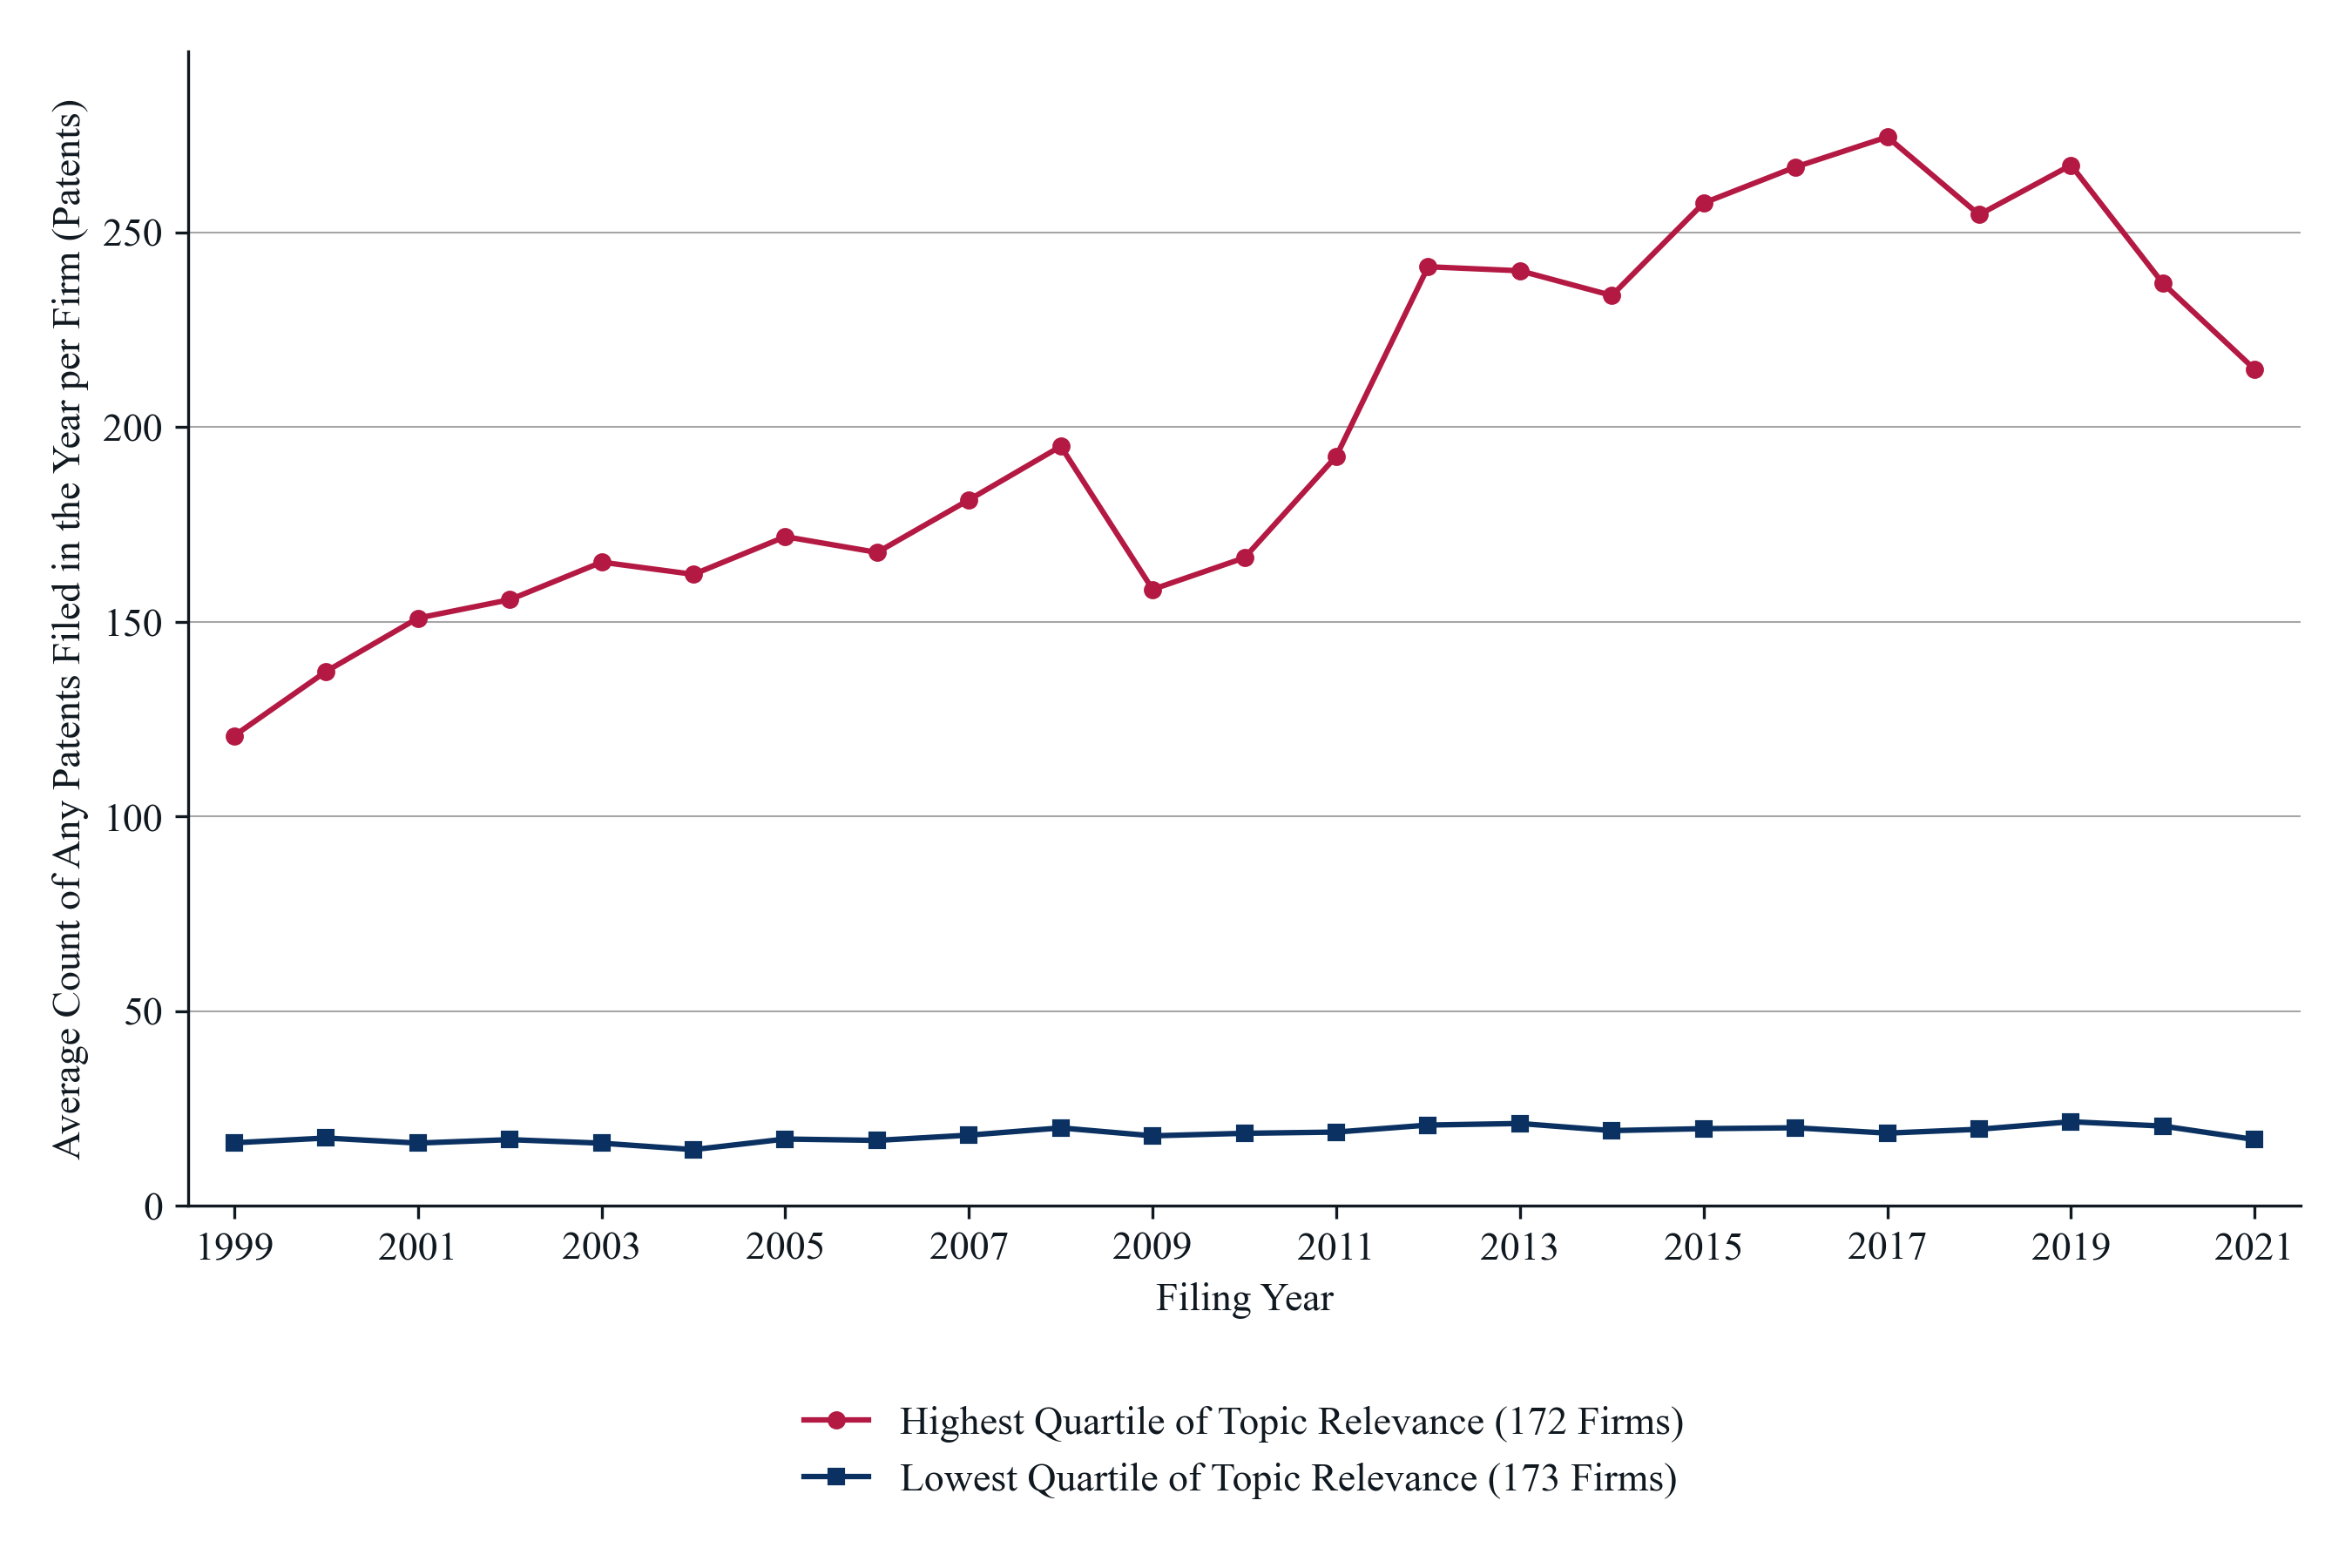

*Notes*: Each line is the average count of any patents filed in the year by the firms of the quartile, any patents meaning all KPSS patents in any CPC class, 1999 to 2021: RED for the highest quartile of topic relevance and BLUE for the lowest. Over the period the highest quartile filed 793,398 patents of any kind (4,613 per firm) and the lowest 73,106 (423 per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the saved table. The analysis sample is the 689 firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any CPC class, filed in 1999 to 2017; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). Topic relevance is the cosine similarity between a firm-level summary of the firm's 10-K Item 1 (Business) sections over its sample fiscal years and the policy summary of legislator statements on consumer data privacy legislation, both written by the language model (T3.8.3, the main measure of T3.9.1 to T3.9.4); a higher score means that the firm's business description is closer to the policy summary. The quartiles are cut within the analysis sample: the highest quartile holds the 172 firms with scores from 0.540 to 0.621 and the lowest the 173 firms with scores from 0.406 to 0.490; the two middle quartiles are not drawn. The average is the quartile's total count in the year divided by its number of firms, which is fixed over the period, so a firm counts zero in a year in which it filed nothing, including years before its listing or after its delisting. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

In [7]:
figure_number = 1
figure_name = "fig_1_average_patent_count_highest_vs_lowest_relevance_quartile"
title = f"Average Count of Any Patents Filed in the Year per Firm, Highest and Lowest Quartiles of Topic Relevance Among Patenting Sample Firms, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Average Count of Any Patents Filed in the Year per Firm (Patents)"
outcome = "mean_patents"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
legend_handles = []
for quartile, table, marker in [(HIGHEST, highest, "o"), (LOWEST, lowest, "s")]:
    line, = axis.plot(table["filing_year"], table[outcome], color=COLOR_BY_NAME[GROUP_COLORS[quartile]], linewidth=1.5, marker=marker, markersize=4,
                      label=f"{GROUP_TITLES[quartile]} ({int(table['n_firms'].iloc[0]):,} Firms)", zorder=3)
    legend_handles.append(line)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(highest[outcome].max(), lowest[outcome].max()) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
# Legend: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room, which moves the X-title and the legend together.
x_title_box = axis.xaxis.label.get_window_extent(renderer)
axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / figure.bbox.width
legend = figure.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=1, frameon=False, handlelength=1.6)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert legend_box.x0 >= margin_pixels and legend_box.x1 <= figure.bbox.width - margin_pixels, f"legend runs from {legend_box.x0 / figure.dpi:.2f} to {legend_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - legend_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert abs(legend_box.y0 - margin_pixels) <= 2, f"legend bottom at {legend_box.y0 / figure.dpi:.2f} inches"
assert axis.get_tightbbox(renderer).y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the top margin"
sample_words = (f"The analysis sample is the {N_ANALYSIS:,} firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any "
                f"CPC class, filed in {PATENTING_START} to {PATENTING_END}; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). "
                f"Topic relevance is {SCORE_WORDS}. The quartiles are cut within the analysis sample: the highest quartile holds the {N_HIGHEST} firms with scores from "
                f"{quartile_summary.loc[HIGHEST, 'score_min']:.3f} to {quartile_summary.loc[HIGHEST, 'score_max']:.3f} and the lowest the {N_LOWEST} firms with scores from "
                f"{quartile_summary.loc[LOWEST, 'score_min']:.3f} to {quartile_summary.loc[LOWEST, 'score_max']:.3f}; the two middle quartiles are not drawn. The average is the quartile's "
                "total count in the year divided by its number of firms, which is fixed over the period, so a firm counts zero in a year in which it filed nothing, including years "
                "before its listing or after its delisting. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period "
                "were not all granted by 2025.")

notes = (f"Each line is the average count of any patents filed in the year by the firms of the quartile, any patents meaning all KPSS patents in any CPC class, {PERIOD_WORDS}: RED for the highest quartile of topic "
         f"relevance and BLUE for the lowest. Over the period the highest quartile filed {int(quartile_summary.loc[HIGHEST, 'patents_period']):,} patents of any kind "
         f"({quartile_summary.loc[HIGHEST, 'patents_period'] / N_HIGHEST:,.0f} per firm) and the lowest {int(quartile_summary.loc[LOWEST, 'patents_period']):,} "
         f"({quartile_summary.loc[LOWEST, 'patents_period'] / N_LOWEST:,.0f} per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the saved table. "
         f"{sample_words}")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 8. Figure 2: average count of privacy patents filed in the year per firm, highest against lowest quartile

The same two lines for privacy patents, the patents with at least one code of the privacy code list as defined in T4.1.2.


**Figure 2. Average Count of Privacy Patents Filed in the Year per Firm, Highest and Lowest Quartiles of Topic Relevance Among Patenting Sample Firms, 1999 to 2021**

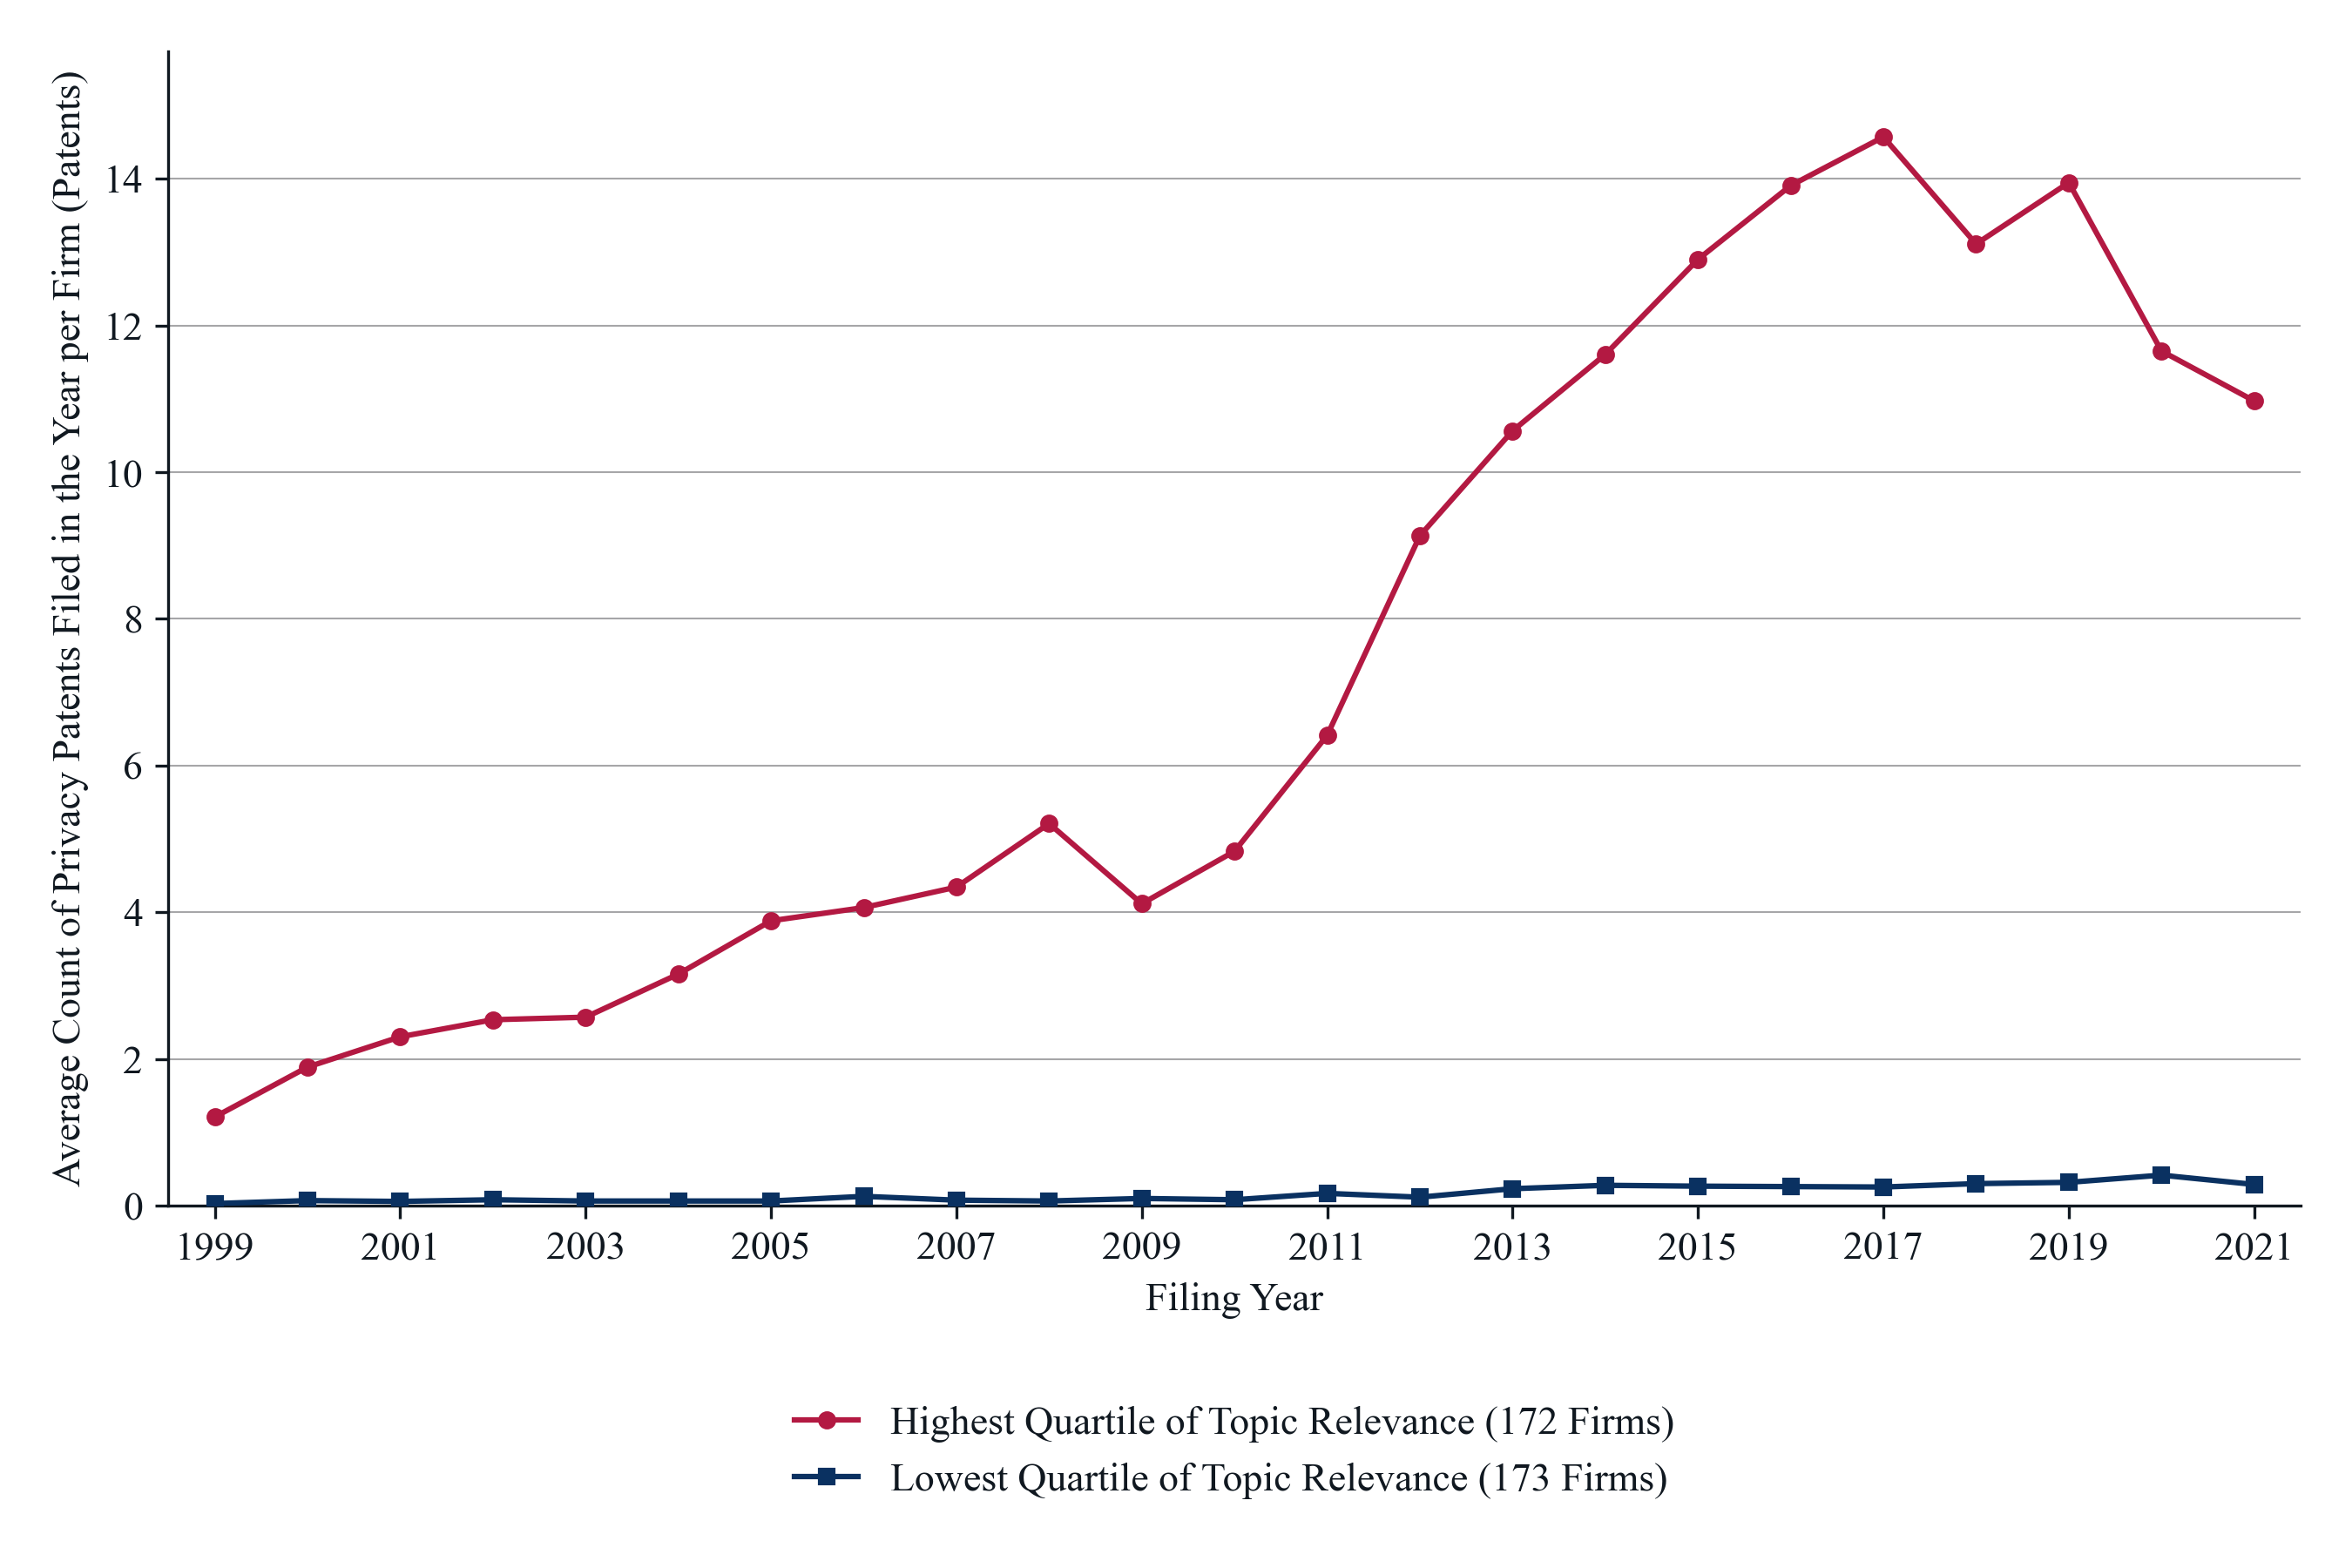

*Notes*: Each line is the average count of privacy patents filed in the year by the firms of the quartile, 1999 to 2021: RED for the highest quartile of topic relevance and BLUE for the lowest. A privacy patent is a KPSS patent that carries at least one of the 72 CPC codes of the project's privacy code list, matched exactly as in T4.1.2. Over the period the highest quartile filed 29,048 privacy patents (168.9 per firm) and the lowest 652 (3.8 per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the saved table. The analysis sample is the 689 firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any CPC class, filed in 1999 to 2017; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). Topic relevance is the cosine similarity between a firm-level summary of the firm's 10-K Item 1 (Business) sections over its sample fiscal years and the policy summary of legislator statements on consumer data privacy legislation, both written by the language model (T3.8.3, the main measure of T3.9.1 to T3.9.4); a higher score means that the firm's business description is closer to the policy summary. The quartiles are cut within the analysis sample: the highest quartile holds the 172 firms with scores from 0.540 to 0.621 and the lowest the 173 firms with scores from 0.406 to 0.490; the two middle quartiles are not drawn. The average is the quartile's total count in the year divided by its number of firms, which is fixed over the period, so a firm counts zero in a year in which it filed nothing, including years before its listing or after its delisting. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

In [8]:
figure_number = 2
figure_name = "fig_2_average_privacy_patent_count_highest_vs_lowest_relevance_quartile"
title = f"Average Count of Privacy Patents Filed in the Year per Firm, Highest and Lowest Quartiles of Topic Relevance Among Patenting Sample Firms, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Average Count of Privacy Patents Filed in the Year per Firm (Patents)"
outcome = "mean_privacy_patents"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
legend_handles = []
for quartile, table, marker in [(HIGHEST, highest, "o"), (LOWEST, lowest, "s")]:
    line, = axis.plot(table["filing_year"], table[outcome], color=COLOR_BY_NAME[GROUP_COLORS[quartile]], linewidth=1.5, marker=marker, markersize=4,
                      label=f"{GROUP_TITLES[quartile]} ({int(table['n_firms'].iloc[0]):,} Firms)", zorder=3)
    legend_handles.append(line)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(highest[outcome].max(), lowest[outcome].max()) * 1.08)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
# Legend: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room, which moves the X-title and the legend together.
x_title_box = axis.xaxis.label.get_window_extent(renderer)
axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / figure.bbox.width
legend = figure.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=1, frameon=False, handlelength=1.6)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert legend_box.x0 >= margin_pixels and legend_box.x1 <= figure.bbox.width - margin_pixels, f"legend runs from {legend_box.x0 / figure.dpi:.2f} to {legend_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - legend_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert abs(legend_box.y0 - margin_pixels) <= 2, f"legend bottom at {legend_box.y0 / figure.dpi:.2f} inches"
assert axis.get_tightbbox(renderer).y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the top margin"
sample_words = (f"The analysis sample is the {N_ANALYSIS:,} firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any "
                f"CPC class, filed in {PATENTING_START} to {PATENTING_END}; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). "
                f"Topic relevance is {SCORE_WORDS}. The quartiles are cut within the analysis sample: the highest quartile holds the {N_HIGHEST} firms with scores from "
                f"{quartile_summary.loc[HIGHEST, 'score_min']:.3f} to {quartile_summary.loc[HIGHEST, 'score_max']:.3f} and the lowest the {N_LOWEST} firms with scores from "
                f"{quartile_summary.loc[LOWEST, 'score_min']:.3f} to {quartile_summary.loc[LOWEST, 'score_max']:.3f}; the two middle quartiles are not drawn. The average is the quartile's "
                "total count in the year divided by its number of firms, which is fixed over the period, so a firm counts zero in a year in which it filed nothing, including years "
                "before its listing or after its delisting. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period "
                "were not all granted by 2025.")

notes = (f"Each line is the average count of privacy patents filed in the year by the firms of the quartile, {PERIOD_WORDS}: RED for the highest quartile of topic relevance and BLUE "
         f"for the lowest. A privacy patent is a KPSS patent that carries at least one of the {N_PRIVACY_CODES} CPC codes of the project's privacy code list, matched exactly as in T4.1.2. "
         f"Over the period the highest quartile filed {int(quartile_summary.loc[HIGHEST, 'privacy_patents_period']):,} privacy patents "
         f"({quartile_summary.loc[HIGHEST, 'privacy_patents_period'] / N_HIGHEST:,.1f} per firm) and the lowest {int(quartile_summary.loc[LOWEST, 'privacy_patents_period']):,} "
         f"({quartile_summary.loc[LOWEST, 'privacy_patents_period'] / N_LOWEST:,.1f} per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the saved table. "
         f"{sample_words}")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))
